In [ ]:
import pandas as pd
diabetes_path = '/content/diabetes.csv'


In [ ]:

diabetes_columns = ['Pregnancies','Glucose','Bloodpressure','Skinthickness','Insulin','bmi','Diabetespedigreefunction','age','Outcome']

In [ ]:
diabetes=pd.read_csv(diabetes_path,names=diabetes_columns)

In [ ]:
diabetes.head(5)

,Pregnancies,Glucose,Bloodpressure,Skinthickness,Insulin,bmi,Diabetespedigreefunction,age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
diabetes.tail(5)

,Pregnancies,Glucose,Bloodpressure,Skinthickness,Insulin,bmi,Diabetespedigreefunction,age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:

print("Rows:",diabetes.shape[0])

768

In [ ]:
print("Column:",diabetes.shape[1])

Column: 9


In [ ]:
print(diabetes.columns.tolist())

['Pregnancies', 'Glucose', 'Bloodpressure', 'Skinthickness', 'Insulin', 'bmi', 'Diabetespedigreefunction', 'age', 'Outcome']


In [ ]:
diabetes.dtypes

,0
Pregnancies,int64
Glucose,int64
Bloodpressure,int64
Skinthickness,int64
Insulin,int64
bmi,float64
Diabetespedigreefunction,float64
age,int64
Outcome,int64


In [ ]:
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   Bloodpressure             768 non-null    int64  
 3   Skinthickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   bmi                       768 non-null    float64
 6   Diabetespedigreefunction  768 non-null    float64
 7   age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
diabetes.describe()

,Pregnancies,Glucose,Bloodpressure,Skinthickness,Insulin,bmi,Diabetespedigreefunction,age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:

input_column = ['Pregnancies','Glucose','Bloodpressure','Skinthickness','Insulin','bmi','Diabetespedigreefunction','age']
target_column = ['Outcome']

print("Input column : ",input_column)
print("Target column : ",target_column)

Input column :  ['Pregnancies', 'Glucose', 'Bloodpressure', 'Skinthickness', 'Insulin', 'bmi', 'Diabetespedigreefunction', 'age']
Target column :  ['Outcome']


In [ ]:
diabetes.duplicated().sum()

np.int64(0)

In [ ]:
import numpy as np

invalid_zero_columns = ['Glucose','Bloodpressure','Skinthickness','Insulin','bmi']


diabetes[invalid_zero_columns] = diabetes[invalid_zero_columns].replace(0,np.nan)

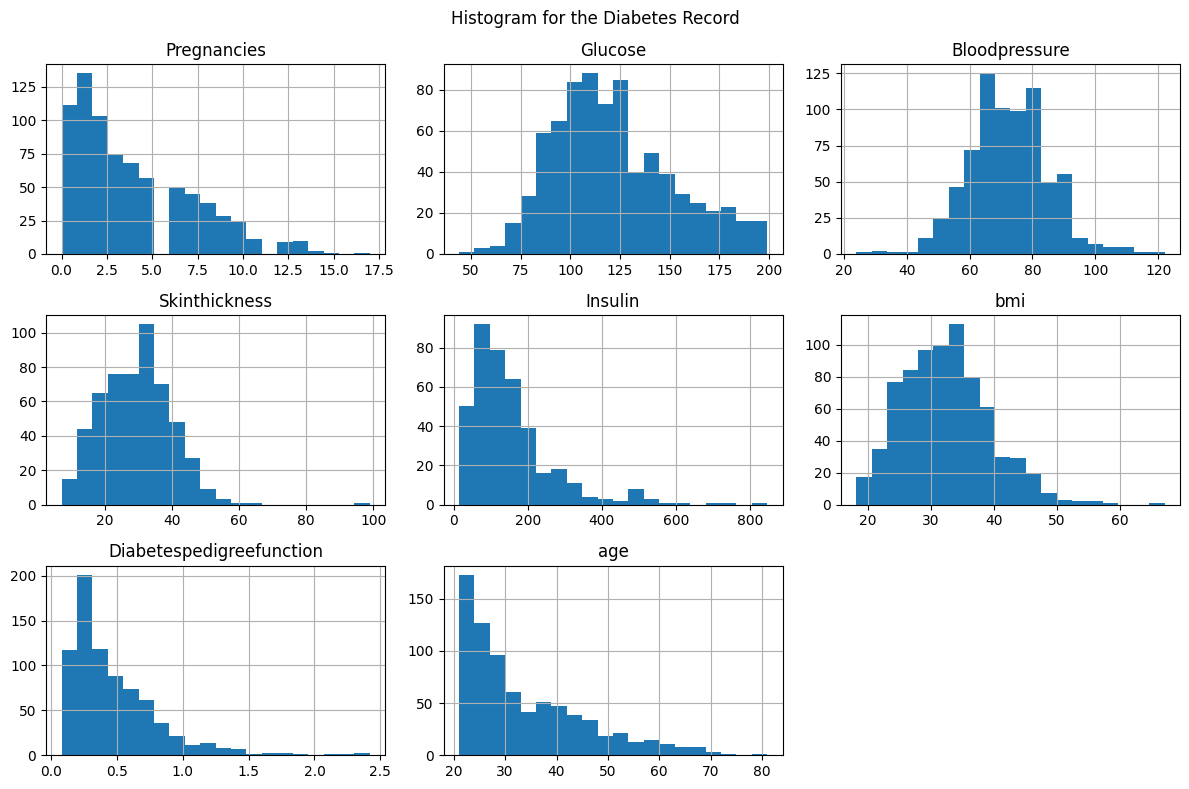

In [ ]:
import matplotlib.pyplot as plt
diabetes[input_column].hist(
    bins=20,
    figsize=(12,8),

)
plt.suptitle("Histogram for the Diabetes Record")
plt.tight_layout()
plt.show()

In [ ]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,5
Bloodpressure,35
Skinthickness,227
Insulin,374
bmi,11
Diabetespedigreefunction,0
age,0
Outcome,0


In [ ]:
diabetes['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


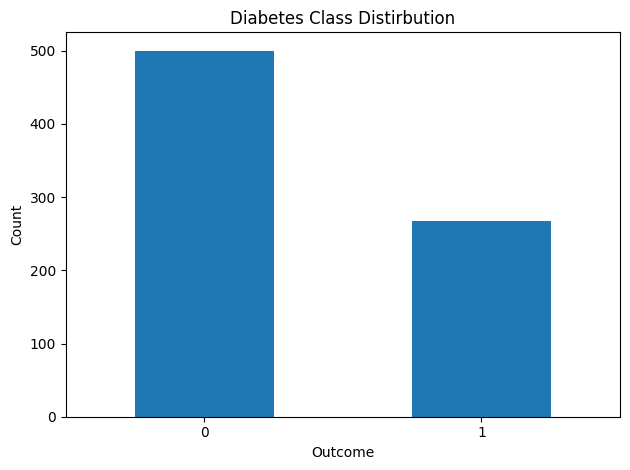

In [ ]:
diabetes["Outcome"].value_counts().sort_index().plot(
    kind='bar'
)

plt.title("Diabetes Class Distirbution")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



In [ ]:
from sklearn.tree import DecisionTreeClassifier
decision_tree_model = DecisionTreeClassifier(
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

In [ ]:
x_diabetes=diabetes.drop("Outcome",axis=1)
y_diabetes=diabetes["Outcome"]

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x_diabetes,y_diabetes , test_size=0.2,random_state=42,stratify=y_diabetes)

In [ ]:
for column in input_column:
  skew_value = diabetes[column].skew()
  if -0.5 <= skew_value <= 0.5:
    print(column, "-> use mean")
  else:
    print(column, "-> use median")

Pregnancies -> use median
Glucose -> use median
Bloodpressure -> use mean
Skinthickness -> use median
Insulin -> use median
bmi -> use median
Diabetespedigreefunction -> use median
age -> use median


In [ ]:
decision_tree_model.fit(
    x_train,
    y_train
)

DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

diabetes_predictions = decision_tree_model.predict(x_test)

accuracy = accuracy_score(y_test, diabetes_predictions)
print("Accuracy : ", accuracy)
print("Confusion Matrix : ")
print(confusion_matrix(y_test, diabetes_predictions))
print("Classification Report : ")
print(classification_report(y_test, diabetes_predictions))

Accuracy :  0.7077922077922078
Confusion Matrix : 
[[63 37]
 [ 8 46]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.89      0.63      0.74       100
           1       0.55      0.85      0.67        54

    accuracy                           0.71       154
   macro avg       0.72      0.74      0.70       154
weighted avg       0.77      0.71      0.71       154



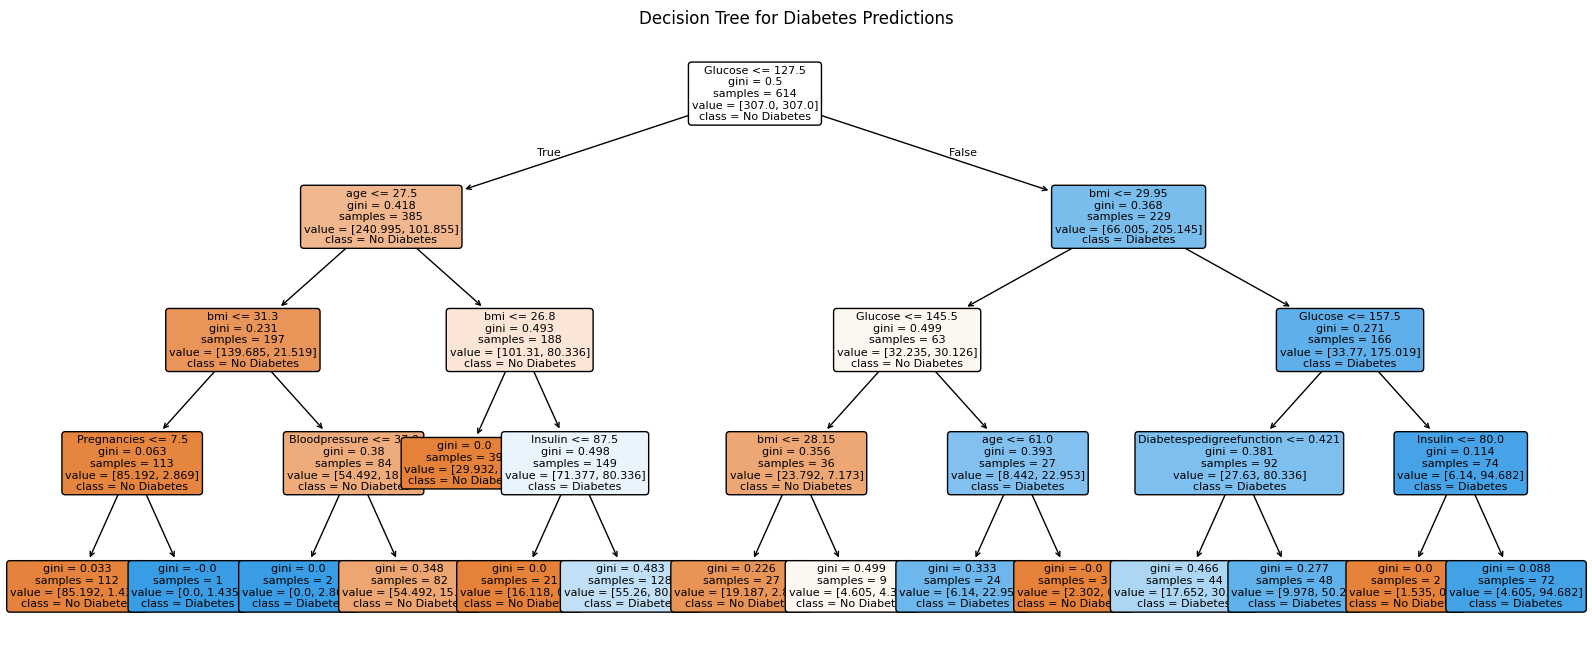

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(
    decision_tree_model,
    feature_names=x_diabetes.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    fontsize=8,
    rounded=True,
)
plt.title("Decision Tree for Diabetes Predictions")
plt.show()

In [ ]:
import pandas as pd

# Define a sample new patient with features matching the input columns
new_patient = pd.DataFrame(columns=x_diabetes.columns)

# Make prediction
patient_prediction = decision_tree_model.predict(new_patient)[0]
print("Predicted class:", patient_prediction)

if patient_prediction == 1:
  print("The patient is predicted to have diabetes.")
else:
  print("The patient is predicted not to have diabetes.")

NameError: name 'x_diabetes' is not defined